# Rollout比較：MSEと相対L2
各stepでReケースを等しい重みで平均します。内挿と外挿は別々に表示します。
既存CSVのみを読み、学習・推論は実行しません。欠損CSVは一覧に表示します。

誤差は物理スケール・流体領域の値です。相対L2はケースごとの比の算術平均です。
overall MSEは異なる単位のu/v/pを含む既存指標なので、成分別も確認してください。
曲線は時刻ごとの誤差であり、時間方向の累積和ではありません。


In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "performance/results").is_dir())
EXPERIMENTS = ["ex005", "ex006", "ex007", "ex008","ex009"]
SPLITS = ["interpolation", "extrapolation"]
LOG_SCALE = False  # 小さい値を比較するときはTrue
SAVE_RESULTS = False  # Trueで比較図と平均CSVを保存
OUTPUT_DIR = ROOT / "performance/results/rollout_comparison"
FIELDS = ["overall", "u", "v", "p"]
METRICS = [f"{m}_{f}" for m in ["mse", "relative_l2"] for f in FIELDS]


In [18]:
data, availability = {}, []
for split in SPLITS:
    for experiment in EXPERIMENTS:
        path = ROOT / "performance/results" / f"{experiment}_baseline" / split / "rollout/rollout_metrics.csv"
        if not path.is_file():
            availability.append(dict(split=split, experiment=experiment, status="CSV missing"))
            continue
        df = pd.read_csv(path)
        required = ["Re", "step", "time", "elapsed_time", *METRICS]
        if not set(required).issubset(df.columns):
            raise ValueError(f"{path}: required columns missing")
        if df.empty or not np.isfinite(df[required].to_numpy(dtype=float)).all():
            raise ValueError(f"{path}: empty data or NaN/Inf")
        if df.duplicated(["Re", "step"]).any() or (df[METRICS] < 0).any().any():
            raise ValueError(f"{path}: duplicate Re/step or negative error")
        df = df.sort_values(["Re", "step"]).reset_index(drop=True)
        expected = pd.MultiIndex.from_product([sorted(df.Re.unique()), sorted(df.step.unique())])
        if not pd.MultiIndex.from_frame(df[["Re", "step"]]).equals(expected):
            raise ValueError(f"{path}: missing Re/step combinations")
        for _, group in df.groupby("step"):
            times = group[["time", "elapsed_time"]].to_numpy()
            if not np.allclose(times, times[0], rtol=0, atol=1e-6):
                raise ValueError(f"{path}: time differs across Re")
        data[(split, experiment)] = df
        availability.append(dict(split=split, experiment=experiment, status="available",
                                 Re=sorted(df.Re.unique()), steps=df.step.nunique()))
display(pd.DataFrame(availability))

for split in SPLITS:
    reference = None
    for experiment in EXPERIMENTS:
        if (split, experiment) not in data:
            continue
        keys = data[(split, experiment)][["Re", "step", "time", "elapsed_time"]].to_numpy()
        if reference is not None and (keys.shape != reference.shape or
                not np.allclose(keys, reference, rtol=0, atol=1e-6)):
            raise ValueError(f"{split}: Re/step/time differs for {experiment}")
        reference = keys
means = {key: df.groupby("step", as_index=False)[["time", "elapsed_time", *METRICS]].mean()
         for key, df in data.items()}
if not means:
    raise ValueError("No rollout CSV found")


,split,experiment,status,Re,steps
0,interpolation,ex005,available,"[35.0, 85.0, 135.0, 185.0, 235.0]",100
1,interpolation,ex006,available,"[35.0, 85.0, 135.0, 185.0, 235.0]",100
2,interpolation,ex007,available,"[35.0, 85.0, 135.0, 185.0, 235.0]",100
3,interpolation,ex008,available,"[35.0, 85.0, 135.0, 185.0, 235.0]",100
4,interpolation,ex009,available,"[35.0, 85.0, 135.0, 185.0, 235.0]",100
5,extrapolation,ex005,available,"[260.0, 270.0, 280.0, 290.0, 300.0]",100
6,extrapolation,ex006,available,"[260.0, 270.0, 280.0, 290.0, 300.0]",100
7,extrapolation,ex007,available,"[260.0, 270.0, 280.0, 290.0, 300.0]",100
8,extrapolation,ex008,available,"[260.0, 270.0, 280.0, 290.0, 300.0]",100
9,extrapolation,ex009,available,"[260.0, 270.0, 280.0, 290.0, 300.0]",100


## 平均誤差の時間変化
上段：MSE、下段：相対L2。列：overall・u・v・p。
CSVを追加したら上から再実行すると比較対象に入ります。


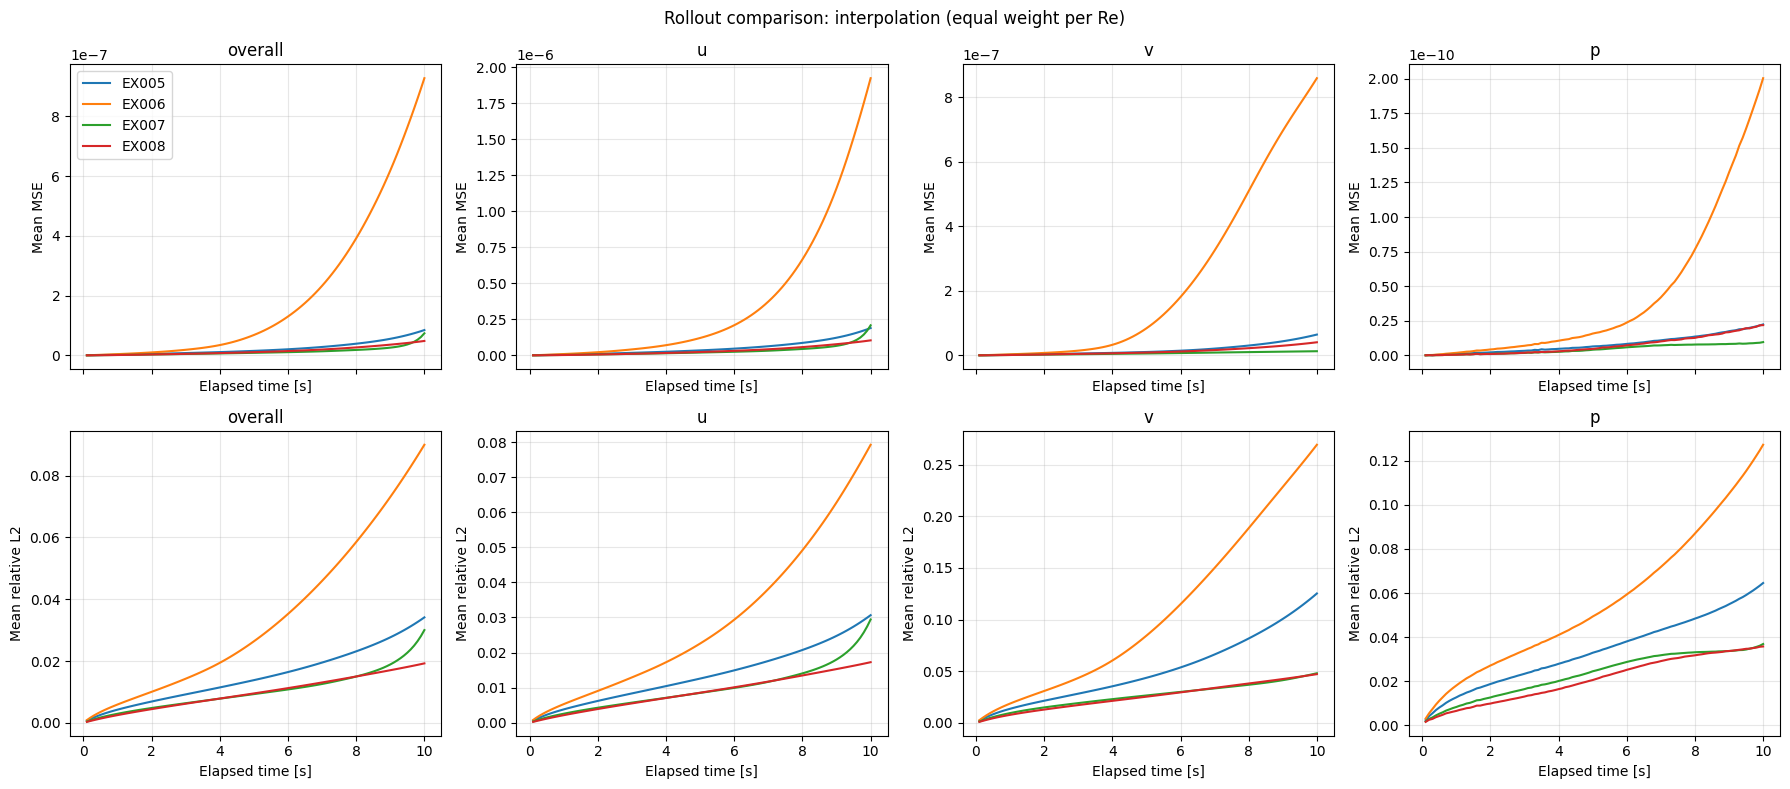

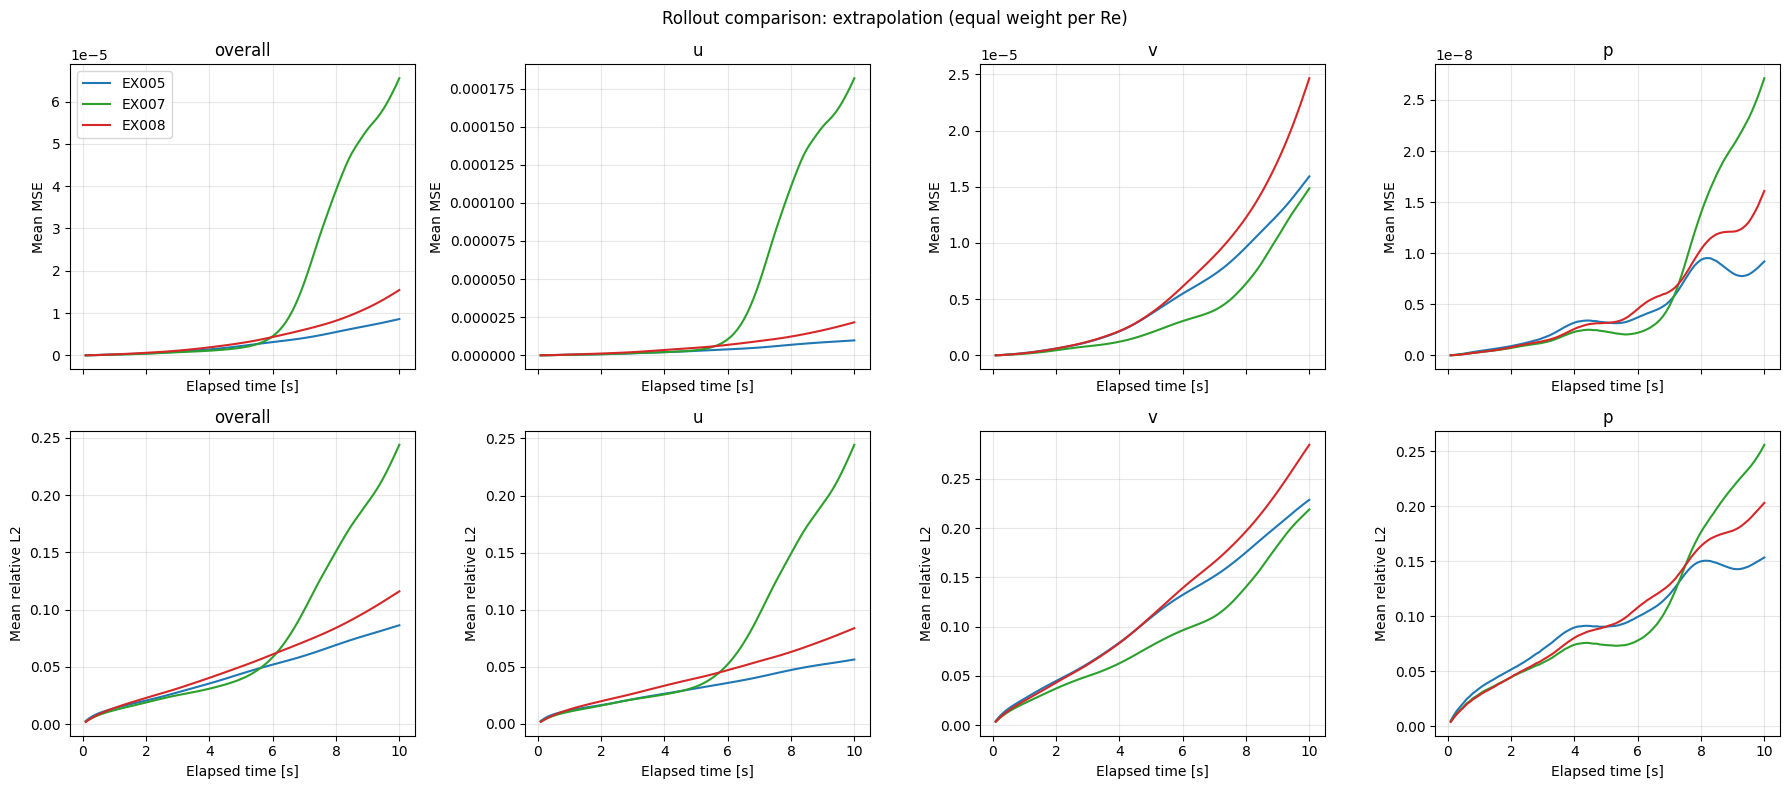

In [13]:
colors = dict(zip(EXPERIMENTS, plt.get_cmap("tab10").colors))
for split in SPLITS:
    available = [e for e in EXPERIMENTS if (split, e) in means]
    if not available:
        continue
    fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, squeeze=False)
    for row, metric in enumerate(["mse", "relative_l2"]):
        for col, field in enumerate(FIELDS):
            ax = axes[row, col]
            for experiment in available:
                mean = means[(split, experiment)]
                ax.plot(mean.elapsed_time, mean[f"{metric}_{field}"],
                        label=experiment.upper(), color=colors[experiment])
            ax.set_title(field)
            ax.set_ylabel("Mean MSE" if metric == "mse" else "Mean relative L2")
            ax.set_xlabel("Elapsed time [s]")
            ax.grid(alpha=0.3)
            if LOG_SCALE:
                ax.set_yscale("log")
    axes[0, 0].legend()
    fig.suptitle(f"Rollout comparison: {split} (equal weight per Re)")
    fig.tight_layout()
    if SAVE_RESULTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / f"{split}_mse_relative_l2.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 要約表
final：最終step、time_mean：各stepの単純平均、peak：Re平均曲線の最大値。
個別Reの最大誤差ではありません。


In [14]:
rows = []
for (split, experiment), mean in means.items():
    for metric in METRICS:
        rows.append(dict(split=split, experiment=experiment, metric=metric,
                         Re_count=data[(split, experiment)].Re.nunique(), steps=len(mean),
                         final=mean[metric].iloc[-1], time_mean=mean[metric].mean(),
                         peak=mean[metric].max()))
    if SAVE_RESULTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        mean.to_csv(OUTPUT_DIR / f"{experiment}_{split}_mean.csv", index=False)
summary = pd.DataFrame(rows)
for split in SPLITS:
    for metric in ["mse", "relative_l2"]:
        subset = summary[(summary.split == split) & summary.metric.str.startswith(metric + "_")]
        if not subset.empty:
            print(f"{split} / {metric}")
            display(subset.pivot(index="experiment", columns="metric", values=["final", "time_mean", "peak"]))
if SAVE_RESULTS:
    summary.to_csv(OUTPUT_DIR / "summary.csv", index=False)
    print(f"Saved: {OUTPUT_DIR}")


interpolation / mse


final                                            \
metric       mse_overall         mse_p         mse_u         mse_v   
experiment                                                           
ex005       8.453577e-08  2.245513e-11  1.892759e-07  6.430892e-08   
ex006       9.280858e-07  2.002962e-10  1.924377e-06  8.596806e-07   
ex007       7.365892e-08  9.663392e-12  2.082738e-07  1.269329e-08   
ex008       4.805581e-08  2.193337e-11  1.037266e-07  4.041886e-08   

               time_mean                                            \
metric       mse_overall         mse_p         mse_u         mse_v   
experiment                                                           
ex005       2.255587e-08  8.025419e-12  5.059124e-08  1.706836e-08   
ex006       1.990197e-07  4.177721e-11  3.657767e-07  2.312406e-07   
ex007       1.210736e-08  4.500308e-12  3.029326e-08  6.024319e-09   
ex008       1.474461e-08  7.069029e-12  3.185517e-08  1.237160e-08   

                    peak                                            
metric       mse_overall         mse_p         mse_u         mse_v  
experiment                                                          
ex005       8.453577e-08  2.245513e-11  1.892759e-07  6.430892e-08  
ex006       9.280858e-07  2.002962e-10  1.924377e-06  8.596806e-07  
ex007       7.365892e-08  9.663392e-12  2.082738e-07  1.269329e-08  
ex008       4.805581e-08  2.193337e-11  1.037266e-07  4.041886e-08

interpolation / relative_l2


final                                            \
metric     relative_l2_overall relative_l2_p relative_l2_u relative_l2_v   
experiment                                                                 
ex005                 0.034127      0.064545      0.030662      0.125293   
ex006                 0.090018      0.127183      0.079234      0.269246   
ex007                 0.030013      0.036905      0.029440      0.048093   
ex008                 0.019232      0.035797      0.017260      0.047213   

                     time_mean                                            \
metric     relative_l2_overall relative_l2_p relative_l2_u relative_l2_v   
experiment                                                                 
ex005                 0.015099      0.033675      0.013625      0.051342   
ex006                 0.033764      0.056302      0.028944      0.106688   
ex007                 0.010361      0.023069      0.009673      0.026208   
ex008                 0.009735      0.020742      0.008737      0.025536   

                          peak                                            
metric     relative_l2_overall relative_l2_p relative_l2_u relative_l2_v  
experiment                                                                
ex005                 0.034127      0.064545      0.030662      0.125293  
ex006                 0.090018      0.127183      0.079234      0.269246  
ex007                 0.030013      0.036905      0.029440      0.048093  
ex008                 0.019232      0.035797      0.017260      0.047213

extrapolation / mse


final                                     time_mean  \
metric     mse_overall         mse_p     mse_u     mse_v mse_overall   
experiment                                                             
ex005         0.000009  9.191510e-09  0.000010  0.000016    0.000003   
ex007         0.000066  2.712621e-08  0.000182  0.000015    0.000015   
ex008         0.000015  1.609099e-08  0.000022  0.000025    0.000004   

                                                    peak                \
metric             mse_p     mse_u     mse_v mse_overall         mse_p   
experiment                                                               
ex005       4.054399e-09  0.000004  0.000005    0.000009  9.523785e-09   
ex007       6.241564e-09  0.000042  0.000004    0.000066  2.712621e-08   
ex008       4.961984e-09  0.000007  0.000007    0.000015  1.609099e-08   

                                
metric         mse_u     mse_v  
experiment                      
ex005       0.000010  0.000016  
ex007       0.000182  0.000015  
ex008       0.000022  0.000025

extrapolation / relative_l2


final                                            \
metric     relative_l2_overall relative_l2_p relative_l2_u relative_l2_v   
experiment                                                                 
ex005                 0.086364      0.153499      0.056403      0.228831   
ex007                 0.244074      0.256037      0.244459      0.219111   
ex008                 0.116017      0.203175      0.083790      0.284762   

                     time_mean                                            \
metric     relative_l2_overall relative_l2_p relative_l2_u relative_l2_v   
experiment                                                                 
ex005                 0.044946      0.093572      0.031605      0.111670   
ex007                 0.076014      0.100200      0.072655      0.090289   
ex008                 0.053871      0.099458      0.041635      0.121769   

                          peak                                            
metric     relative_l2_overall relative_l2_p relative_l2_u relative_l2_v  
experiment                                                                
ex005                 0.086364      0.153499      0.056403      0.228831  
ex007                 0.244074      0.256037      0.244459      0.219111  
ex008                 0.116017      0.203175      0.083790      0.284762